# Kinematic diffraction of Silicon

This notebook walks through kinematic electron diffraction with pyEMAPS, step by step. It
follows the *si_dif.py* sample, but runs one step per cell, so you can stop at each step, look at
the result, change a value and run it again.

You'll:

1. load a crystal and look at its data;
2. set the microscope controls;
3. generate a diffraction pattern and look inside it;
4. display it, as spots and as CBED disks;
5. see how the pattern changes with the zone axis, the tilt and the camera length.

**Kinematic theory in brief.** In the kinematic approximation, each electron is scattered at most
once. A reflection *g* is excited when its reciprocal lattice point lies close to the Ewald sphere;
how far it is from the sphere is its *excitation error*. The pattern's geometry, which beams appear
and where, comes out right, and it's quick to calculate. Intensities in thicker crystals need
dynamic (Bloch wave) theory instead; see the [dynamic diffraction notebook](si_bloch.ipynb).

pyEMAPS' simulations follow the kinematic and dynamic theory in J. C. H. Spence and J. M. Zuo,
*Electron Microdiffraction* (Plenum, 1992). This notebook points to its chapters along the way.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment:

```
pip install pyemaps jupyter
```

The [pyEMAPS documentation](https://emlab-solutions.github.io/pyemaps/) has the full reference;
the [Kinematic diffraction guide](https://emlab-solutions.github.io/pyemaps/user_guide/kinematic.html)
covers the same ground.

## Step 1: Import pyEMAPS

`Crystal` holds a crystal's data and runs the simulations. `EMC` (electron microscope controls)
holds the microscope settings. `DPList` collects diffraction patterns for `showDif` to display.

In [1]:
from importlib.metadata import version

from pyemaps import EMC, Crystal, DPList, showDif

print('pyEMAPS', version('pyemaps'))

pyEMAPS 2.1.1.dev11


## Step 2: Load a crystal

pyEMAPS has a library of built-in crystals. Load Silicon and print its data: the name and the
type of its thermal (Debye-Waller) factors, the cell constants (*a*, *b*, *c* in Å and *α*, *β*,
*γ* in degrees), the atoms (element, fractional position, Debye-Waller factor, occupancy) and the
space group (number and setting). Silicon is cubic, space group 227 (*Fd*-3*m*), with one atom in
the asymmetric unit.

In [2]:
silicon = Crystal.from_builtin('Silicon')
print(silicon)

Crystal name: Silicon dw iso
cell: 5.4307 5.4307 5.4307 90.0 90.0 90.0
SI 0.125 0.125 0.125 0.4668 1.00
spg: 227 2


Other crystals load the same way. To see the whole library:

In [3]:
print(Crystal.list_all_builtin_crystals())

['Aluminium', 'AluminiumOxide', 'Aluminium_FCC', 'BariumTitanate_180k', 'BariumTitanate_270k', 'BariumTitanate_Tetra', 'BiMnO3', 'Boron_Tetra', 'CadmiumSelenide_Hex', 'CadmiumSulfide_Cubic', 'CadmiumSulfide_Hex', 'Chromium_BCC', 'CopperOxide', 'Copper_FCC', 'CoSb3_Skutterudite', 'Cu2O_Cuprite', 'Diamond', 'ErbiumPyrogermanate', 'FePd_Tetra', 'FeS2_Pyrite', 'GalliumAntimonide', 'GalliumArsenide', 'GalliumNitride', 'Germanium', 'Gold_FCC', 'IndiumArsenide', 'LaMnO3', 'LeadZirconateTitanate', 'Li2MnO3', 'limno2', 'NaFeO2', 'Nb3Sn', 'Pentacene', 'Silicon', 'StrontiumTitanate', 'TelluriumDioxide', 'TinDioxide_RT', 'TitaniumDioxide_Anatase', 'TitaniumDioxide_Rutile', 'TungstenDiselenide', 'VanadiumDioxide_RT', 'ZincOxide', 'Zinc_HCP', 'ZirconiumNitride']


Your own crystals load from a CIF file with `Crystal.from_cif`, or from an EMAPS `.xtl` file
with `Crystal.from_xtl`.

## Step 3: Set the microscope controls

An `EMC` object holds the settings of the simulated microscope. Printing it shows every setting
with its unit; a setting you've changed also shows its default. The ones this notebook changes:

| Setting | Meaning |
|---|---|
| `zone` | the zone axis [*uvw*]: the crystal direction along the beam |
| `tilt` | the crystal tilt away from the zone axis, in x and y (degrees) |
| `cl` | the camera length, in mm: how magnified the pattern is |
| `vt` | the high voltage, in kV: it sets the electron wavelength |

`EMC()` with no arguments gives the defaults: zone axis [001], no tilt, 1000 mm and 200 kV.

In [4]:
emc = EMC()
print(emc)

Electron microscope controls
  Mode                      Normal
  Zone axis                 [0 0 1]
  Tilt (x, y)               (0, 0) degrees
  Shift (x, y)              (0, 0)
  Camera length             1000 mm
  High voltage              200 kV
  Horizontal axis           (0 0 0), chosen by pyEMAPS
  Detector pixel size       25 µm
  Detector size             512 pixels
  Objective aperture        1
Simulation controls
  Excitation error range    0.3 to 2
  Max. reciprocal vector    3.5 1/Å
  Beta perturbation cutoff  0.1
  Intensity cutoff, scale   0, 5
  Max. g-list index         6
  Max. zone axis index      5
  Diagonalization cutoff    10
  Sampling points           8
  Sample thickness          200 Å


### The electron wavelength

The high voltage *E* sets the electron wavelength. At these energies the electrons travel at a
large fraction of the speed of light, so the wavelength needs the relativistic correction:

$$\lambda = \frac{h}{\sqrt{2 m_0 e E \left(1 + \dfrac{eE}{2 m_0 c^2}\right)}}$$

The Ewald sphere, of radius $K = 1/\lambda$, is then huge compared with Silicon's reciprocal
lattice:

In [5]:
import math

h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0   # SI units


def wavelength(kv):
    """The relativistic electron wavelength in Å, at a high voltage in kV."""
    E = kv * 1e3
    return h / math.sqrt(2 * m0 * e * E * (1 + e * E / (2 * m0 * c**2))) * 1e10


g111 = math.sqrt(3) / 5.4307      # length of Silicon's (1 1 1), in 1/Å (a = 5.4307 Å, Step 2)
for kv in (100, 200, 300):
    lam = wavelength(kv)
    print(f'{kv} kV: wavelength {lam:.5f} Å, Ewald sphere radius {1 / lam:4.1f} 1/Å, '
          f'{1 / lam / g111:3.0f} times |g(1 1 1)|')

100 kV: wavelength 0.03701 Å, Ewald sphere radius 27.0 1/Å,  85 times |g(1 1 1)|
200 kV: wavelength 0.02508 Å, Ewald sphere radius 39.9 1/Å, 125 times |g(1 1 1)|
300 kV: wavelength 0.01969 Å, Ewald sphere radius 50.8 1/Å, 159 times |g(1 1 1)|


Over a few reciprocal lattice spacings, a sphere that large is nearly flat. So when the beam
runs along a zone axis, a whole plane of reciprocal lattice points lies close to the sphere, and
they're all excited at once: that's the zone axis pattern. Spence and Zuo's chapter 2, *The
Geometry of CBED Patterns*, works through this geometry.

## Step 4: Generate a diffraction pattern

`generateDP` simulates the pattern. It returns two things: the controls it used, and the
pattern. Any control left unset gets its default, and pyEMAPS fills in the ones it chooses itself,
such as the crystal's horizontal axis (`xaxis`).

In [6]:
emc, pattern = silicon.generateDP(em_controls=EMC(zone=(0, 0, 1)))

print('Kikuchi lines:   ', pattern.nklines)
print('Diffracted beams:', pattern.ndisks)
print('HOLZ lines:      ', pattern.nhlines)

Kikuchi lines:    24
Diffracted beams: 25
HOLZ lines:       0


Each diffracted beam has a center and a radius, in pattern coordinates (which span -75 to 75
across the pattern), and its Miller indices. The first one is the direct beam, (0 0 0):

In [7]:
for disk in pattern.disks[:5]:
    x, y, r, h, k, l = disk
    print(f'({h:2d} {k:2d} {l:2d})   center ({x:7.2f}, {y:7.2f})   radius {r:.2f}')

( 0  0  0)   center (   0.00,    0.00)   radius 2.00
( 2 -2  0)   center (  -9.24,   -9.24)   radius 2.00
(-2  2  0)   center (   9.24,    9.24)   radius 2.00
(-2 -2  0)   center (  -9.24,    9.24)   radius 2.00
( 2  2  0)   center (   9.24,   -9.24)   radius 2.00


The beams are the reflections of the zero-order Laue zone (ZOLZ): the *g* = (*hkl*) with
*g*·[*uvw*] = 0, here *l* = 0.

Which of them appear depends on the **structure factor**, the sum of the scattering of the atoms
in the unit cell:

$$F_{\mathbf g} = \sum_j f_j(\mathbf g)\, e^{2\pi i\, \mathbf g \cdot \mathbf r_j}$$

where $f_j$ is atom *j*'s scattering factor and $\mathbf r_j$ its position. Silicon has the
diamond structure: a face-centred cubic lattice with two atoms per lattice point, a quarter of
the cube diagonal apart. $F_{\mathbf g}$ is zero unless *h*, *k* and *l* are all odd, or all even
with *h* + *k* + *l* a multiple of 4. So (1 0 0), (2 1 0) and (2 0 0) are missing, while
(2 2 0) and (4 0 0) appear.

In the kinematic theory, a beam's intensity at sample thickness *t* is

$$I_{\mathbf g} \propto |F_{\mathbf g}|^2\, \frac{\sin^2(\pi t s_{\mathbf g})}{(\pi s_{\mathbf g})^2}$$

where $s_{\mathbf g}$ is the excitation error. At the Bragg condition, $s_{\mathbf g} = 0$, it grows
as $t^2$ without limit, which can't last: for strong reflections, after a few tens of
nanometres the diffracted beam would carry more than the incident beam. Beyond that, the dynamic
theory takes over (Spence and Zuo, chapter 3, *Theory*).

Each Kikuchi line has two end points and an intensity level (5 is the strongest):

In [8]:
for line in pattern.klines[:4]:
    x1, y1, x2, y2, intensity = line
    print(f'({x1:7.2f}, {y1:7.2f}) to ({x2:7.2f}, {y2:7.2f})   intensity {intensity}')

(  75.00,  -56.53) to ( -56.53,   75.00)   intensity 5
(  56.53,  -75.00) to ( -75.00,   56.53)   intensity 5
( -56.53,  -75.00) to (  75.00,   56.53)   intensity 5
(  56.53,   75.00) to ( -75.00,  -56.53)   intensity 5


## Step 5: Display the pattern

`showDif` displays the patterns in a `DPList`. Add the pattern, with the controls that made it,
and show it. The diffracted beams are the blue spots, labeled with their Miller indices; the grey
lines are the Kikuchi lines.

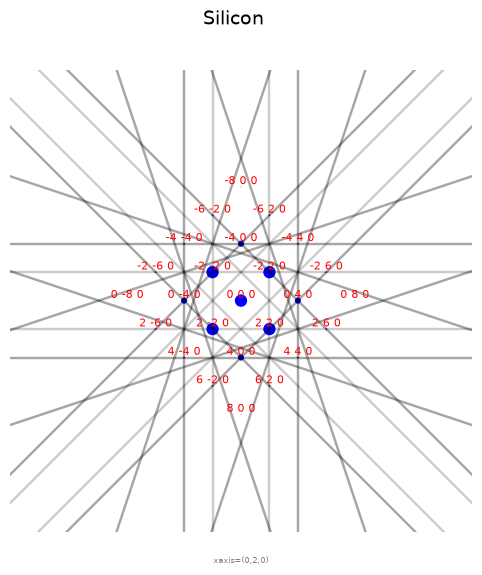

In [9]:
patterns = DPList('Silicon')
patterns.add(emc, pattern)
showDif(patterns)

`showDif`'s options turn parts of the plot on and off: `kShow=False` hides the Kikuchi lines
and `iShow=False` the Miller indices. Without them, the spot pattern alone shows the four-fold
symmetry of the [001] zone:

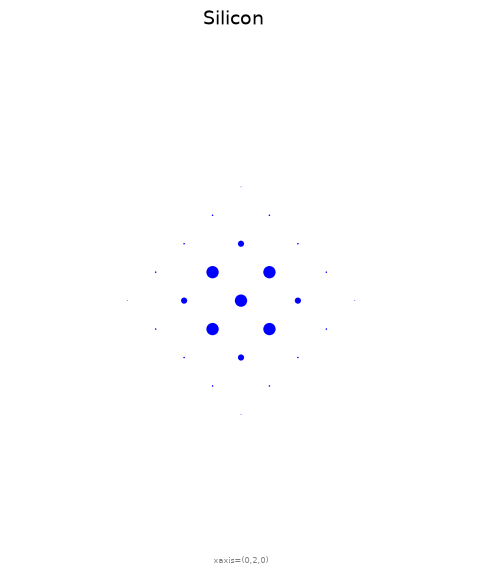

In [10]:
showDif(patterns, kShow=False, iShow=False)

**Kikuchi lines** come from electrons that first lose a little energy and change direction in
the crystal (diffuse, inelastic scattering), then Bragg-diffract. They're fixed to the crystal,
not to the beam, so they move when the crystal tilts while the spots stay put. That makes them
useful for finding the crystal's orientation.

## Step 6: CBED mode

In convergent beam electron diffraction (CBED), the beam converges onto the sample in a cone, so
each diffracted beam becomes a disk instead of a spot. Disks also show **HOLZ lines**: fine lines
from reflections in the higher-order Laue zones (HOLZ), the planes of reciprocal lattice points
above the ZOLZ.

The Ewald sphere curves up through these planes, and meets the *n*-th one on a ring of radius

$$G_n \approx \sqrt{2 n H K}$$

where *H* is the spacing of the planes along the zone axis and $K = 1/\lambda$. HOLZ reflections
have long *g* vectors, so a small change in the lattice parameters or the high voltage moves
their lines visibly. That's how CBED measures lattice parameters and strain (Spence and Zuo,
chapter 2).

Generate the pattern in CBED mode with `mode=2`. `dsize` sets the disk size. This uses the [111]
zone axis, where Silicon's HOLZ lines show clearly; hiding the Kikuchi lines leaves the disks and
the HOLZ lines.

HOLZ lines: 51


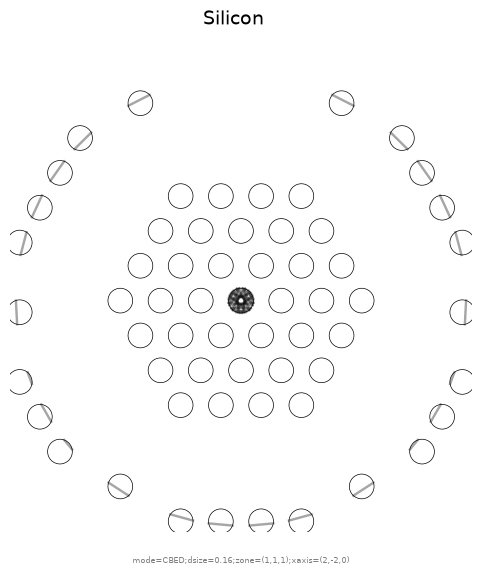

In [11]:
emc, pattern = silicon.generateDP(mode=2, dsize=0.16, em_controls=EMC(zone=(1, 1, 1)))
print('HOLZ lines:', pattern.nhlines)

cbed = DPList('Silicon', mode=2)
cbed.add(emc, pattern)
showDif(cbed, kShow=False, iShow=False)

## Step 7: Change one control at a time

A pattern's geometry depends on the microscope settings. Generating patterns over a range of one
setting, with everything else fixed, shows what that setting does. The patterns go into one
`DPList`, and `layout='table'` shows them side by side, each captioned with the settings that
differ from the defaults.

### Zone axis

Each zone axis gives a different section through the reciprocal lattice, so a different pattern
and symmetry: four-fold at [001], two-fold at [011], and six-fold at [111]. A longer camera length
(2500 mm) spreads the spots out, and hiding the Kikuchi lines leaves the spot pattern.

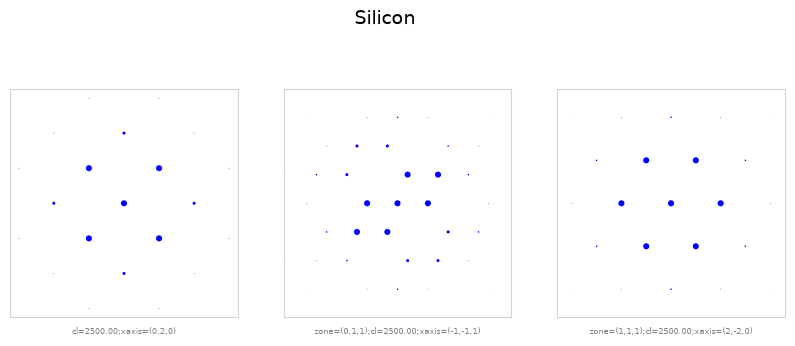

In [12]:
zones = DPList('Silicon')
for zone in [(0, 0, 1), (0, 1, 1), (1, 1, 1)]:
    emc, pattern = silicon.generateDP(em_controls=EMC(zone=zone, cl=2500))
    zones.add(emc, pattern)

showDif(zones, layout='table', kShow=False, iShow=False)

### Tilt

Tilting the crystal a little away from the zone axis moves the Kikuchi lines across the pattern,
while the spots stay where they are. It also changes which reflections are excited, so spots
appear and disappear at the edges.

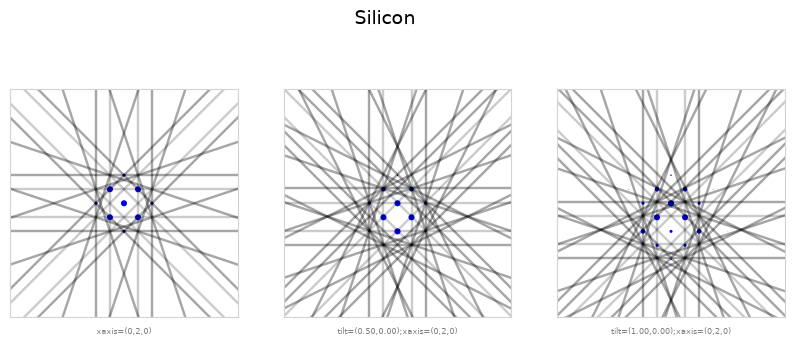

In [13]:
tilts = DPList('Silicon')
for tilt_x in [0.0, 0.5, 1.0]:
    emc, pattern = silicon.generateDP(em_controls=EMC(tilt=(tilt_x, 0.0)))
    tilts.add(emc, pattern)

showDif(tilts, layout='table', iShow=False)

### Camera length

The camera length *L* magnifies the pattern: a reflection with spacing *d* lands at
*R* = λ*L*/*d* from the center, where λ is the electron wavelength. So every distance grows in
proportion to *L*: from 2000 mm to 4000 mm, the (2 -2 0) spot moves twice as far from the center.
(At much shorter camera lengths, the spots crowd together under their labels.)

camera length 2000 mm: (2 -2 0) at (-18.47, -18.47)
camera length 3000 mm: (2 -2 0) at (-27.71, -27.71)
camera length 4000 mm: (2 -2 0) at (-36.94, -36.94)


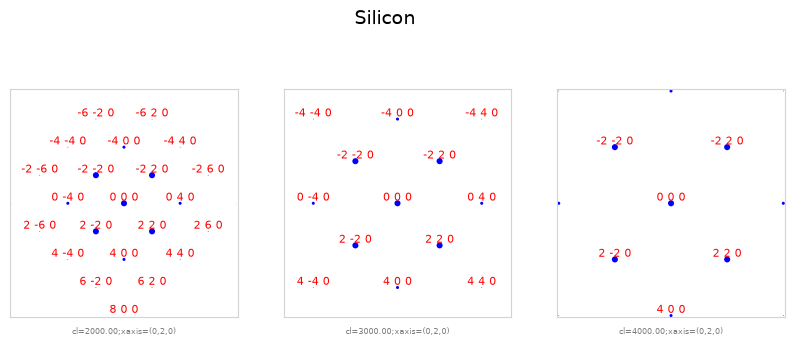

In [14]:
lengths = DPList('Silicon')
for cl in [2000, 3000, 4000]:
    emc, pattern = silicon.generateDP(em_controls=EMC(cl=cl))
    lengths.add(emc, pattern)
    spot = next(d for d in pattern.disks if tuple(d)[3:] == (2, -2, 0))
    print(f'camera length {cl:4d} mm: (2 -2 0) at ({spot.c.x:6.2f}, {spot.c.y:6.2f})')

showDif(lengths, layout='table', kShow=False)

## Step 8: Save the figures

`bSave=True` also saves each figure as a PNG, in the `dif` folder of the pyEMAPS data folder:
the folder named by the `PYEMAPS_DATA` environment variable, or the current folder if it isn't
set. The file name is printed.

image saved to: C:\pyemaps_data\dif\Silicon-20261114095337.png


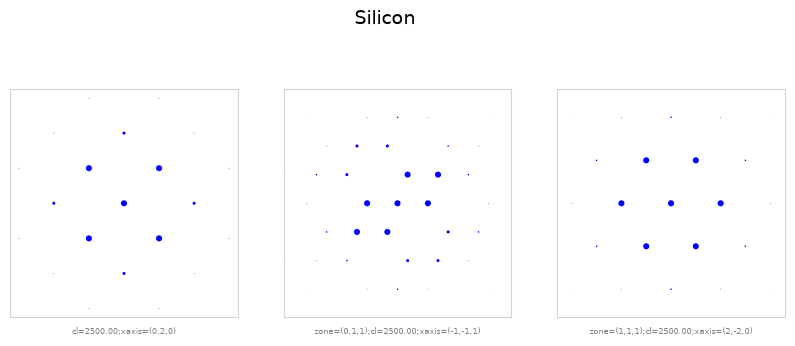

In [15]:
showDif(zones, layout='table', kShow=False, iShow=False, bSave=True)

## Going further: many patterns in parallel

Each pattern takes a moment, so for long series *si_dif.py* runs the simulations in parallel
processes. Its `generate_kinematic_patterns` function makes six patterns, one per value of a
control, and you can call it here too. pyEMAPS installs the samples as `pyemaps.samples`:

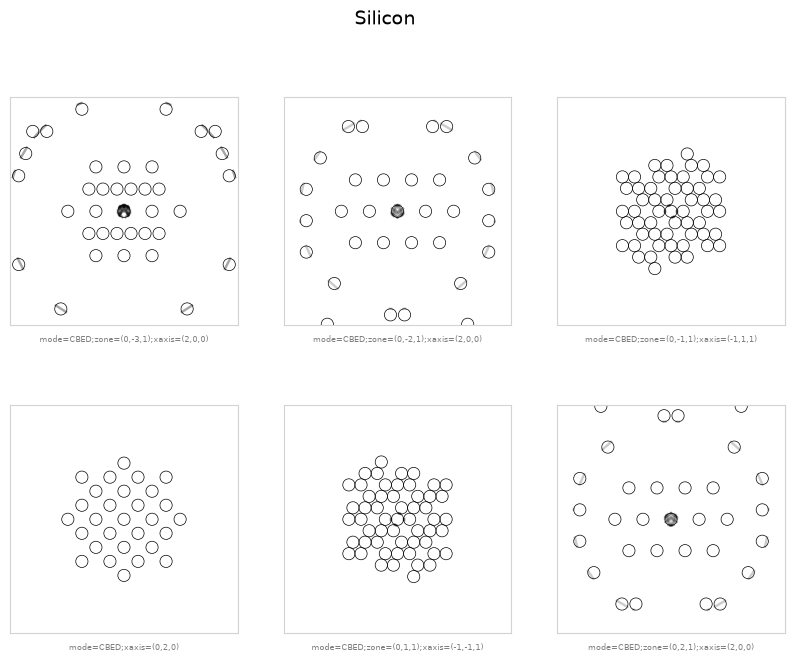

In [16]:
from pyemaps.samples.si_dif import generate_kinematic_patterns

series = generate_kinematic_patterns('zone', mode=2)
showDif(series, layout='table', kShow=False, iShow=False)

To write your own parallel code, see *si_dif.py*, which `pyemaps -cp samples` copies into a
*pyemaps_samples* folder. In a notebook on Windows, the function each process runs must come from
an importable module, such as `pyemaps.samples.si_dif` or a `.py` file of your own; a function
defined in a notebook cell can't be sent to another process.

## Try it yourself

1. **Another crystal.** Load `Germanium`, which has Silicon's structure with a larger cell. Which
   way do the spots move?
2. **High voltage.** Make [111] CBED patterns at 100 kV and 200 kV (`EMC(zone=(1, 1, 1), vt=100)`).
   How do the HOLZ lines change, and why?
3. **Find the zone.** Make patterns at [012] and [013], and compare their symmetry with [001].
4. **Forbidden reflections.** At [011], find the (2 0 0)-type positions in the spot pattern. Are
   they there? What does Silicon's structure factor say about them? In a real [011] pattern they
   often show up anyway, by double diffraction: (1 1 -1) followed by (1 -1 1) adds up to
   (2 0 0). Only the dynamic theory includes that.

## Next

- The dynamic diffraction notebook, [si_bloch.ipynb](si_bloch.ipynb): Bloch wave CBED patterns
  and their intensities.
- [Kinematic diffraction guide](https://emlab-solutions.github.io/pyemaps/user_guide/kinematic.html)
  and the [`generateDP` reference](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.generateDP).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 2, *The Geometry of CBED Patterns*: zone axes, Laue zones, HOLZ lines and the camera
  length;
- chapter 3, *Theory*: the kinematic and dynamic theory of electron diffraction.